In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, List
import asyncio
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_mcp_adapters.client import MultiServerMCPClient
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [5]:
llm = ChatGroq(model = "openai/gpt-oss-120b")

In [6]:
SERVERS = { 
    "AI NewsLetter Research": {
        "transport": "stdio",
        "command": "C:\\Users\\bsais\\anaconda3\\Scripts\\uv.exe",
        "args": [
            "run",
            "fastmcp",
            "run",
            "C:\\D Drive\\Karm\\Projects\\AI-Newsletter\\mcp_server.py"
       ]
    }
}

In [7]:
class NewsletterState(TypedDict):
    
    arxiv_research: str
    ai_news_research: str
    github_research: str
    product_hunt_research: str
    final_md: str

In [8]:
async def research_data(state: NewsletterState):
    
    client = MultiServerMCPClient(SERVERS)
    tools = await client.get_tools()

    named_tools = {}
    for tool in tools:
        named_tools[tool.name] = tool

    print("Available tools:", named_tools.keys())

    # with open("./research/github.md", "r", encoding="utf-8") as file:
    #     github = file.read()

    # with open("./research/news.md", "r", encoding="utf-8") as file:
    #     news = file.read()

    # with open("./research/papers.md", "r", encoding="utf-8") as file:
    #     papers = file.read()

    # with open("./research/products.md", "r", encoding="utf-8") as file:
    #     products = file.read()

    # return {
    #     "arxiv_research": papers,
    #     "ai_news_research": news,
    #     "github_research": github,
    #     "product_hunt_research": products
    # }

In [9]:
def data_agg_md(state: NewsletterState):
    
    raw_data = f"""
    ArXiv Research: {state.get("arxiv_research", "None")}
    Ai News : {state.get("ai_news_research", "None")}
    Github Trending Repos: {state.get("github_research", "None")}
    Product Hunt: {state.get("product_hunt_research", "None")}
    """
    
    system_prompt = """
    You are an expert tech newsletter editor. 
    Your goal is to digest raw research and format it into a highly engaging and concise markdown newsletter.
    Use clear headings, bullet points, and bold text for emphasis. 
    Include an intro paragraph and a short conclusion.
    """

    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=f"Here is the raw research data: \n {raw_data}")
    ]

    # response = llm.invoke(messages)
    print("Hi I am from data agg")

    # return {"final_md": response.content}

In [10]:
def final_html(state: NewsletterState):
    print ("I am from final_html node")
    return state

In [11]:
graph = StateGraph(NewsletterState)

graph.add_node("research_data", research_data)
graph.add_node("data_agg_md", data_agg_md)
graph.add_node("final_html", final_html)

In [12]:
graph.add_edge(START, 'research_data')
graph.add_edge("research_data", "data_agg_md")
graph.add_edge("data_agg_md", "final_html")
graph.add_edge("final_html", END)

workflow = graph.compile()

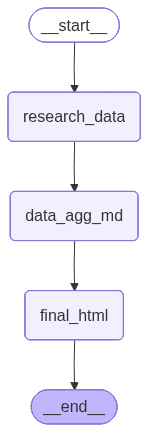

In [13]:
workflow

In [14]:
initial_state = {}
Newsletter = workflow.invoke(initial_state)

TypeError: No synchronous function provided to "research_data".
Either initialize with a synchronous function or invoke via the async API (ainvoke, astream, etc.)

In [ ]:
print(Newsletter)

{'arxiv_research': '# AI Newsletter Research Results - Research Papers\n\n## Featured Research Papers\n\n1. **Retrieval-Augmented Question Answering over Scientific Literature for the Electron-Ion Collider**\n   - **Publisher:** arXiv / Semantic Scholar\n   - **Description:** By Tina. J. Jat, T. Ghosh, Karthik Suresh. To harness the power of Language Models in answering domain specific specialized technical questions, Retrieval Augmented Generation (RAG) is been used widely. In this work, we have developed a Q\\&A application inspired by the Retrieval Augmented Generation (RAG), which is comprised of an in-house database indexed on the arXiv articles related to the Electron-Ion Collider (EIC) experiment - one of the largest international scientific collaboration and incorporated an open-source LLaMA model for ...\n   - **Possible Impact:** To harness the power of Language Models in answering domain specific specialized technical questions, Retrieval Augmented Generation (RAG) is been u

In [ ]:
print(Newsletter["final_md"])

# 🤖 AI Research & News Weekly  
*Your quick‑hit roundup of the hottest papers, headlines, repos, and products.*  

---  

## 📚 Featured Research Papers  

| # | Paper | Why It Matters | 📥 Download |
|---|-------|----------------|------------|
| **1** | **Retrieval‑Augmented QA for the Electron‑Ion Collider** | Shows how a domain‑specific RAG system can answer technical questions using an in‑house arXiv index and an open‑source LLaMA model. A blueprint for scientific‑assistant bots. | [PDF](https://arxiv.org/pdf/2604.02259v1) |
| **2** | **Grounded Token Initialization for New Vocabulary in LMs** | Reveals that naïve “mean‑embedding” init collapses new tokens; proposes a geometry‑aware init that speeds up learning for recommendation‑focused vocabularies. | [PDF](https://arxiv.org/pdf/2604.02324v1) |
| **3** | **Omni123: 3‑D Native Foundation Models with Limited Data** | Unifies text‑to‑2D and text‑to‑3D generation, letting a single model synthesize coherent 3‑D assets despite scarce 3‑D